# 04 — Exploratory Data Analysis for Classification

This notebook studies the high-demand versus not-high-demand task using the published chronological dataset. It audits the class definition learned from positive training outcomes, measures imbalance and prevalence over time, compares predictor distributions between classes, and checks whether category-level or temporal shifts could affect classifier evaluation. The fixed demand threshold is kept separate from the model probability threshold.

## Objectives

- Verify the published high-demand definition without using validation or test to set it.
- Quantify class balance overall, over time, and across broad product segments.
- Measure how strongly historical demand, price, and channel features separate the classes.
- Detect prevalence drift across training, validation, and final-test periods.
- Translate the evidence into suitable baselines, metrics, and threshold-selection rules.


## 1. Reproducible setup and data contract

The notebook reads the immutable publication selected by CURRENT.json, verifies its checksum, and loads only fields needed for classification EDA. All threshold calculations are audited against training data; validation and test are descriptive holdouts and never redefine the class.


In [10]:
from pathlib import Path
import hashlib
import json
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from sklearn.metrics import balanced_accuracy_score, f1_score, precision_score, recall_score
from IPython.display import Markdown, display

SEED = 42
ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "src/data/process_data.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the fashion-demand-ml project.")
sys.path.insert(0, str(ROOT))
import importlib
import src.visualization.style as chart_style
importlib.reload(chart_style)
from src.visualization.style import (
    BLUE, CORAL, GOLD, GRID, INK, MUTED, SPLIT_COLORS, TEAL, VIOLET,
    apply_style, display_es, es, format_number, format_percent, feature_label, add_source, add_title,
)
apply_style()

processed_dir = ROOT / "data/processed"
pointer = json.loads((processed_dir / "CURRENT.json").read_text(encoding="utf-8"))
run_dir = (processed_dir / pointer["run_dir"]).resolve()
if not run_dir.is_relative_to(processed_dir.resolve()) or pointer.get("preview"):
    raise ValueError("CURRENT.json does not reference a valid complete publication.")

summary = json.loads((run_dir / "summary.json").read_text(encoding="utf-8"))
checksums = json.loads((run_dir / "checksums.json").read_text(encoding="utf-8"))
dataset_path = run_dir / "article_week.csv.gz"
digest = hashlib.sha256()
with dataset_path.open("rb") as stream:
    for block in iter(lambda: stream.read(4 * 1024 * 1024), b""):
        digest.update(block)
if digest.hexdigest() != checksums[dataset_path.name]:
    raise ValueError("The article-week dataset changed after publication.")

use_columns = [
    "week", "target_week", "article_id", "split",
    "sales", "mean_price", "online_share",
    "lag_1_sales", "lag_4_sales",
    "rolling_4w_sales_mean", "rolling_4w_sales_std",
    "rolling_4w_active_weeks", "rolling_12w_sales_mean",
    "rolling_12w_sales_std", "rolling_12w_active_weeks",
    "sales_trend_4w", "rolling_4w_online_share",
    "index_group_name", "target_next_week_sales", "target_high_demand",
]
data = pd.read_csv(
    dataset_path,
    usecols=use_columns,
    dtype={"article_id": "string"},
    parse_dates=["week", "target_week"],
)
split_order = ["train", "validation", "test"]
train = data.loc[data["split"].eq("train")].copy()
target = "target_high_demand"
units_target = "target_next_week_sales"
assert set(data["split"].unique()) == set(split_order)
assert len(train) == summary["split_counts"]["train"]

CLASS_COLORS = {0: "#98A2B3", 1: VIOLET}
PASTEL_RAINBOW = ["#E2C94C", "#6FA8FF", "#B28DFF", "#FFB36B", "#65D6A6", "#F27DAA"]

def style_axis(ax, xlabel=None, ylabel=None):
    ax.set_xlabel(xlabel or "", fontweight="bold", color=INK)
    ax.set_ylabel(ylabel or "", fontweight="bold", color=INK)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color=GRID, linewidth=.7, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)

def format_legend(ax, **kwargs):
    legend = ax.legend(
        frameon=True, fancybox=True, facecolor="white", edgecolor=GRID, **kwargs
    )
    legend.get_frame().set_linewidth(.8)
    return legend

def center_axis_title(ax):
    fig = ax.figure
    title_artist = ax.title
    title_artist.set_visible(False)
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    content_box = ax.get_tightbbox(renderer)
    axes_box = ax.get_window_extent(renderer)
    title_artist.set_visible(True)
    content_center = (content_box.x0 + content_box.x1) / 2
    title_artist.set_x((content_center - axes_box.x0) / axes_box.width)

def center_figure_title(fig):
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    boxes = [ax.get_tightbbox(renderer) for ax in fig.axes if ax.get_visible()]
    if fig._suptitle is not None and boxes:
        left = min(box.x0 for box in boxes)
        right = max(box.x1 for box in boxes)
        fig._suptitle.set_x(((left + right) / 2 - fig.bbox.x0) / fig.bbox.width)

def finish_figure(fig, title, source="H&M article-week dataset"):
    add_title(fig, title)
    add_source(fig, f"Source: {source}")
    center_figure_title(fig)

def wilson_interval(successes, totals, z=1.96):
    rate = successes / totals
    denominator = 1 + z**2 / totals
    centre = (rate + z**2 / (2 * totals)) / denominator
    margin = z * np.sqrt(
        rate * (1 - rate) / totals + z**2 / (4 * totals**2)
    ) / denominator
    return centre - margin, centre + margin

print("Run:", run_dir.name)
print("Rows loaded:", f"{es(len(data)):,}")
print("Training rows:", f"{es(len(train)):,}")


Run: 20261024T182146-1559e91a
Rows loaded: 1.887.139
Training rows: 1.326.434


## 2. Fixed high-demand definition and overall imbalance

The production pipeline defines high demand from the 75th percentile of strictly positive next-week training sales, using the next observed integer and applying it unchanged to every split. This is a class-definition policy, not the classifier probability cutoff that will later be tuned on validation data.


,value
definition,target_next_week_sales >= threshold
reference_population,positive target_next_week_sales rows in train only
training_quantile,"0,75"
threshold_units,16


,article_weeks,high_demand_rows,prevalence,first_target_week,last_target_week
split,,,,,
train,1.326.434,264.283,"19,92%",24/12/2018,24/02/2020
validation,271.215,57.814,"21,32%",02/03/2020,08/06/2020
test,289.490,61.201,"21,14%",15/06/2020,14/09/2020


,threshold_units,training_prevalence
positive_training_quantile,,
0.500000,6,"39,11%"
0.550000,7,"35,68%"
0.600000,8,"32,81%"
0.650000,10,"28,29%"
0.700000,12,"24,86%"
0.750000,16,"19,92%"
0.800000,21,"15,84%"
0.850000,28,"12,11%"
0.900000,42,"7,85%"


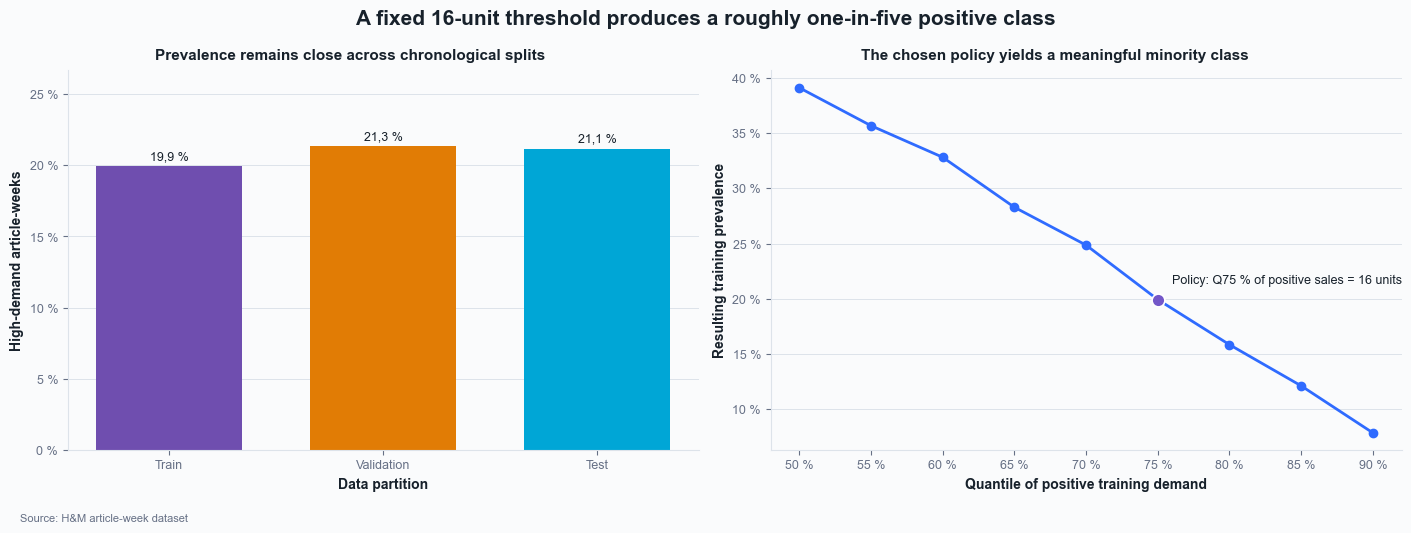

In [11]:
classification = summary["classification_target"]
threshold = int(classification["threshold_units"])
training_quantile = float(classification["training_quantile"])

positive_train = train.loc[train[units_target].gt(0), units_target]
recomputed_threshold = int(max(
    1,
    positive_train.quantile(training_quantile, interpolation="higher"),
))
expected_target = data[units_target].ge(threshold).astype("int8")
assert recomputed_threshold == threshold
assert data[target].isin([0, 1]).all()
assert data[target].eq(expected_target).all()

split_summary = data.groupby("split").agg(
    article_weeks=(target, "size"),
    high_demand_rows=(target, "sum"),
    prevalence=(target, "mean"),
    first_target_week=("target_week", "min"),
    last_target_week=("target_week", "max"),
).reindex(split_order)

policy = pd.Series({
    "definition": classification["definition"],
    "reference_population": classification["reference_population"],
    "training_quantile": training_quantile,
    "threshold_units": threshold,
}, name="value")
display_es(policy.to_frame())
display_es(split_summary.style.format({
    "article_weeks": "{:,.0f}",
    "high_demand_rows": "{:,.0f}",
    "prevalence": "{:.2%}",
    "first_target_week": "{:%d/%m/%Y}",
    "last_target_week": "{:%d/%m/%Y}",
}))

candidate_quantiles = np.arange(.50, .91, .05)
candidate_rows = []
for quantile in candidate_quantiles:
    candidate_threshold = int(max(
        1, positive_train.quantile(quantile, interpolation="higher")
    ))
    candidate_rows.append({
        "positive_training_quantile": quantile,
        "threshold_units": candidate_threshold,
        "training_prevalence": train[units_target].ge(candidate_threshold).mean(),
    })
threshold_sensitivity = pd.DataFrame(candidate_rows).set_index(
    "positive_training_quantile"
)
display_es(threshold_sensitivity.style.format({
    "threshold_units": "{:.0f}",
    "training_prevalence": "{:.2%}",
}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.3), layout="constrained")
bars = axes[0].bar(
    [split.title() for split in split_order],
    split_summary["prevalence"],
    color=[SPLIT_COLORS[split] for split in split_order],
    width=.68, zorder=2,
)
for bar, value in zip(bars, split_summary["prevalence"]):
    axes[0].annotate(
        f"{es(value):.1%}",
        (bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 5), textcoords="offset points",
        ha="center", color=INK, fontsize=9,
    )
axes[0].set_ylim(0, split_summary["prevalence"].max() * 1.25)
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_title("Prevalence remains close across chronological splits", fontweight="bold", color=INK)
style_axis(axes[0], "Data partition", "High-demand article-weeks")

axes[1].plot(
    threshold_sensitivity.index,
    threshold_sensitivity["training_prevalence"],
    color=BLUE, marker="o", linewidth=2,
)
selected_position = np.abs(threshold_sensitivity.index - training_quantile).argmin()
selected = threshold_sensitivity.iloc[selected_position]
axes[1].scatter(
    [training_quantile], [selected["training_prevalence"]],
    color=VIOLET, edgecolor="white", linewidth=1.2, s=85, zorder=3,
)
axes[1].annotate(
    f"Policy: Q{es(training_quantile):.0%} of positive sales = {format_number(threshold)} units",
    (training_quantile, selected["training_prevalence"]),
    xytext=(10, 12), textcoords="offset points", color=INK, fontsize=9,
)
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_title("The chosen policy yields a meaningful minority class", fontweight="bold", color=INK)
style_axis(axes[1], "Quantile of positive training demand", "Resulting training prevalence")
for ax in axes:
    center_axis_title(ax)
finish_figure(fig, "A fixed 16-unit threshold produces a roughly one-in-five positive class")
plt.show()


## 3. Prevalence over time

Weekly prevalence reveals whether the aggregate class balance hides seasonal or abrupt changes. Lines retain the project's fixed split colours; the dashed reference is the overall training prevalence.


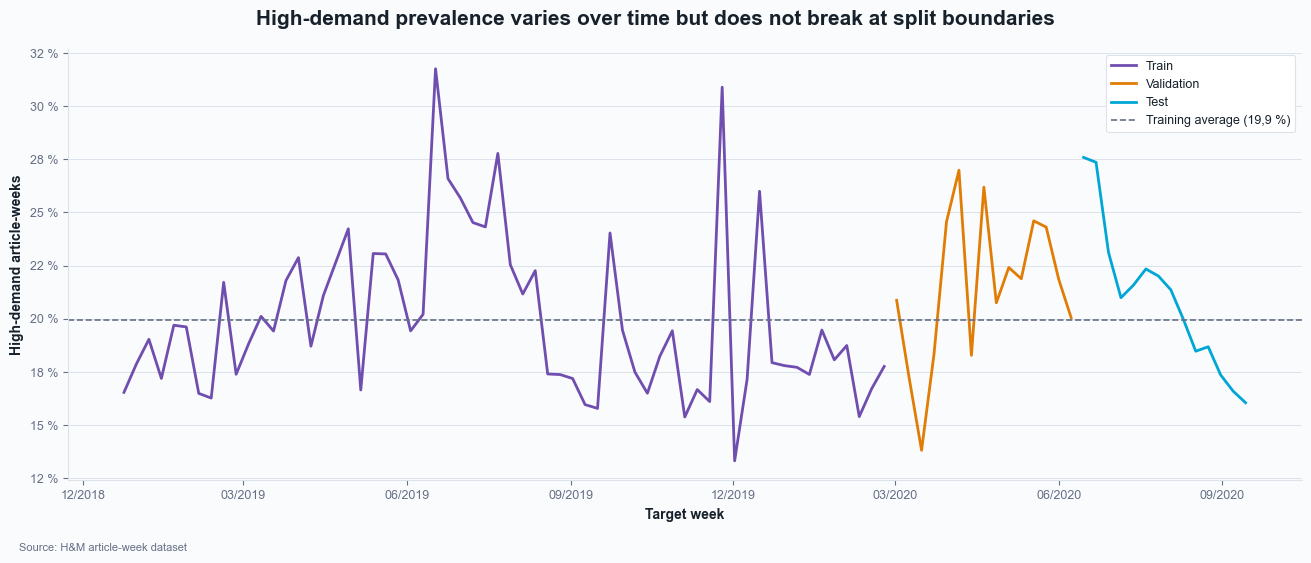

In [12]:
weekly_prevalence = (
    data.groupby(["target_week", "split"], observed=True)[target]
    .agg(prevalence="mean", article_weeks="size")
    .reset_index()
)
training_prevalence = float(split_summary.loc["train", "prevalence"])

fig, ax = plt.subplots(figsize=(13, 5.6), layout="constrained")
for split in split_order:
    subset = weekly_prevalence.loc[
        weekly_prevalence["split"].eq(split)
    ].sort_values("target_week")
    ax.plot(
        subset["target_week"], subset["prevalence"],
        color=SPLIT_COLORS[split], linewidth=2,
        label=split.title(),
    )
ax.axhline(
    training_prevalence, color=MUTED, linestyle="--", linewidth=1.2,
    label=f"Training average ({es(training_prevalence):.1%})",
)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.yaxis.set_major_formatter(PercentFormatter(1))
style_axis(ax, "Target week", "High-demand article-weeks")
format_legend(ax, loc="upper right")
finish_figure(fig, "High-demand prevalence varies over time but does not break at split boundaries")
plt.show()


## 4. Predictor separation between classes

Standardised mean differences compare predictors on a common scale. They describe association with the class, not causality. Empirical cumulative distributions then show the complete shape for four representative predictors without overplotting millions of rows.


,label,not_high_mean,high_mean,standardised_mean_difference,observations
feature,,,,,
rolling_4w_online_share,4-week online share,"0,683","0,663","-0,055",1.216.732
online_share,Current-week online share,"0,666","0,663","-0,008",1.326.434
mean_price,Current-week mean price,"0,028","0,029","+0,032",1.326.434
rolling_12w_active_weeks,Active weeks in 12-week history,"8,037","8,485","+0,110",1.326.434
sales_trend_4w,4-week sales trend,"-1,107","5,018","+0,170",1.326.434
rolling_4w_active_weeks,Active weeks in 4-week history,"2,895","3,505","+0,493",1.326.434
rolling_4w_sales_std,4-week sales variability,"2,981","19,051","+0,731",1.326.434
lag_4_sales,Sales 4 weeks ago,"6,639","42,199","+0,732",1.326.434
rolling_12w_sales_std,12-week sales variability,"6,489","26,853","+0,777",1.326.434


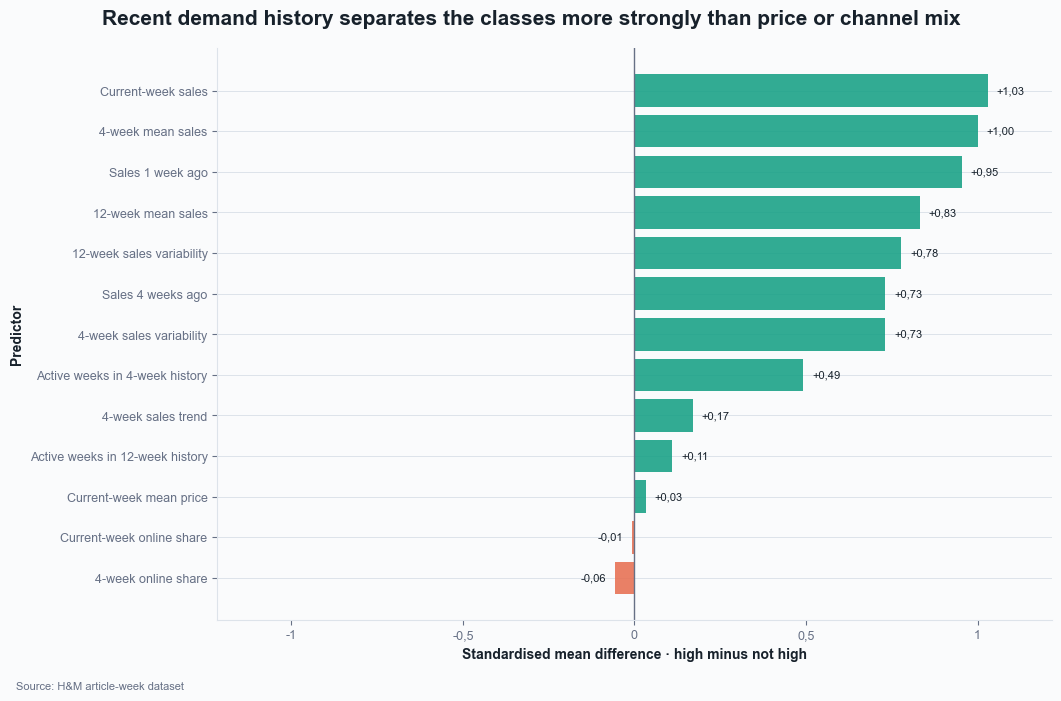

In [13]:
numeric_features = {feature: feature_label(feature) for feature in [
    "sales", "lag_1_sales", "lag_4_sales",
    "rolling_4w_sales_mean", "rolling_12w_sales_mean",
    "rolling_4w_sales_std", "rolling_12w_sales_std",
    "rolling_4w_active_weeks", "rolling_12w_active_weeks",
    "sales_trend_4w", "mean_price", "online_share", "rolling_4w_online_share",
]}

effect_rows = []
for feature, label in numeric_features.items():
    frame = train[[feature, target]].dropna()
    negative = frame.loc[frame[target].eq(0), feature]
    positive = frame.loc[frame[target].eq(1), feature]
    pooled_sd = np.sqrt((negative.var(ddof=1) + positive.var(ddof=1)) / 2)
    smd = (positive.mean() - negative.mean()) / pooled_sd if pooled_sd else np.nan
    effect_rows.append({
        "feature": feature,
        "label": label,
        "not_high_mean": negative.mean(),
        "high_mean": positive.mean(),
        "standardised_mean_difference": smd,
        "observations": len(frame),
    })

feature_separation = (
    pd.DataFrame(effect_rows)
    .set_index("feature")
    .sort_values("standardised_mean_difference")
)
display_es(feature_separation[[
    "label", "not_high_mean", "high_mean",
    "standardised_mean_difference", "observations",
]].style.format({
    "not_high_mean": "{:,.3f}",
    "high_mean": "{:,.3f}",
    "standardised_mean_difference": "{:+.3f}",
    "observations": "{:,.0f}",
}))

plot_effects = feature_separation.dropna(subset=["standardised_mean_difference"])
fig, ax = plt.subplots(figsize=(10.5, 7), layout="constrained")
values = plot_effects["standardised_mean_difference"]
colors = np.where(values.ge(0), TEAL, CORAL)
bars = ax.barh(plot_effects["label"], values, color=colors, alpha=.88, zorder=2)
ax.axvline(0, color=MUTED, linewidth=1)
offset = max(abs(values).max() * .025, .015)
for bar, value in zip(bars, values):
    ax.text(
        value + (offset if value >= 0 else -offset),
        bar.get_y() + bar.get_height() / 2,
        f"{es(value):+.2f}",
        va="center", ha="left" if value >= 0 else "right",
        color=INK, fontsize=8,
    )
limit = max(abs(values).max() * 1.18, .2)
ax.set_xlim(-limit, limit)
style_axis(ax, "Standardised mean difference · high minus not high", "Predictor")
finish_figure(fig, "Recent demand history separates the classes more strongly than price or channel mix")
plt.show()


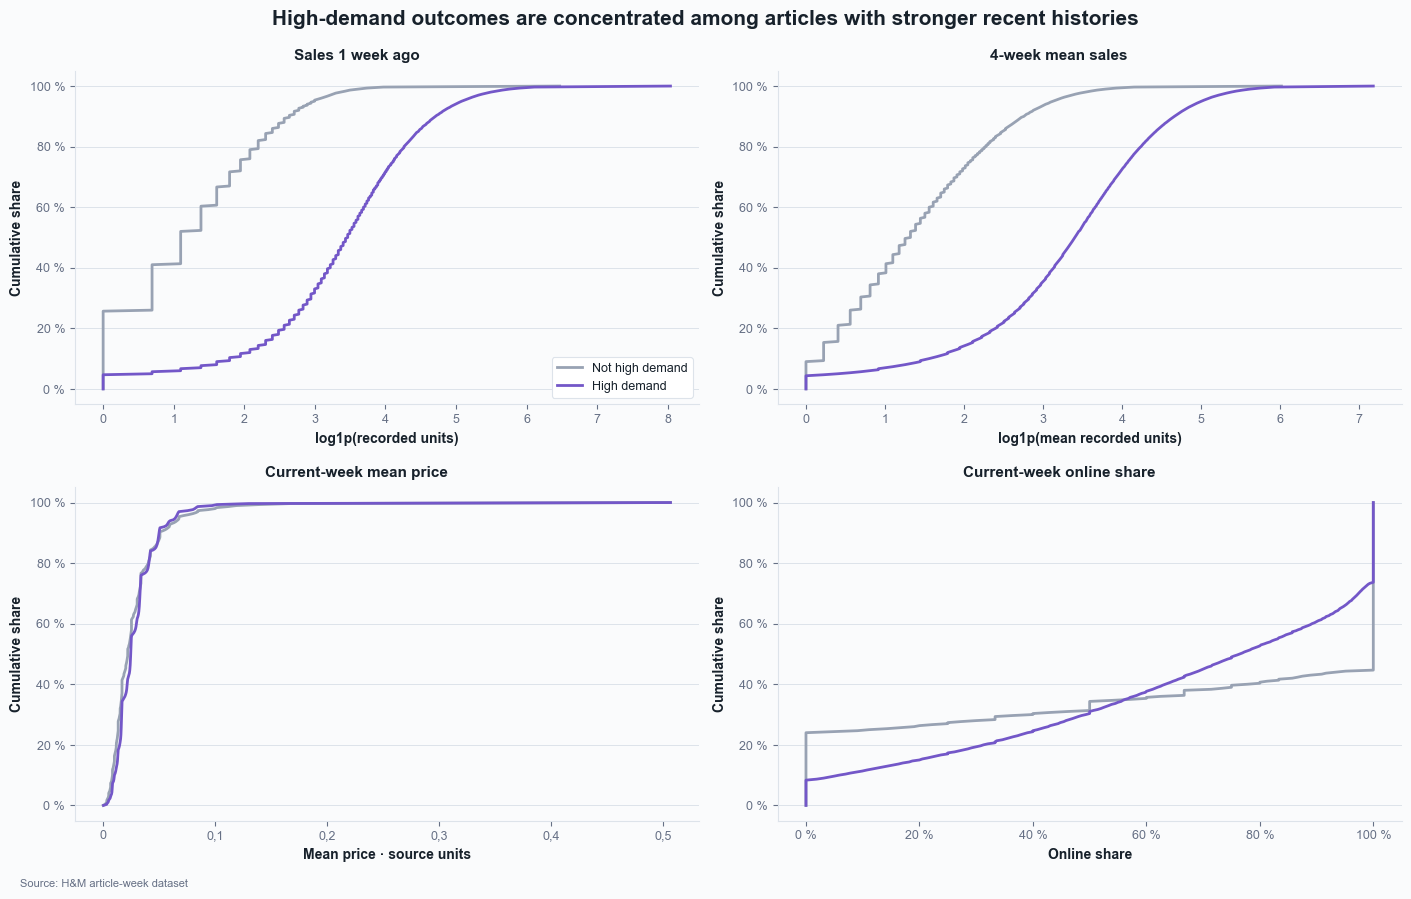

In [14]:
ecdf_specs = [
    ("lag_1_sales", "log1p(recorded units)", "log1p"),
    ("rolling_4w_sales_mean", "log1p(mean recorded units)", "log1p"),
    ("mean_price", "Mean price · source units", "identity"),
    ("online_share", "Online share", "percent"),
]
probabilities = np.linspace(0, 1, 301)
fig, axes = plt.subplots(2, 2, figsize=(14, 9), layout="constrained")
for ax, (feature, xlabel, transform) in zip(axes.flat, ecdf_specs):
    for class_value, class_label in [(0, "Not high demand"), (1, "High demand")]:
        values = train.loc[train[target].eq(class_value), feature].dropna().to_numpy()
        if transform == "log1p":
            values = np.log1p(np.clip(values, 0, None))
        quantiles = np.quantile(values, probabilities)
        ax.plot(
            quantiles, probabilities,
            color=CLASS_COLORS[class_value], linewidth=2,
            label=class_label,
        )
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    if transform == "percent":
        ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_title(feature_label(feature), fontweight="bold", color=INK)
    style_axis(ax, xlabel, "Cumulative share")
    center_axis_title(ax)
format_legend(axes[0, 0], loc="lower right")
finish_figure(fig, "High-demand outcomes are concentrated among articles with stronger recent histories")
plt.show()


## 5. Product segment and channel comparisons

Broad product segments avoid unstable rates for tiny leaf categories. Wilson intervals show binomial uncertainty. Channel bands are ordered by the observed online share and use a sequential scale because they represent increasing values of one variable.


,article_weeks,high_demand_rows,prevalence,lower_95,upper_95
index_group_name,,,,,
Baby/Children,235.570,3.194,"1,36%","1,31%","1,40%"
Menswear,158.477,14.531,"9,17%","9,03%","9,31%"
Sport,45.302,11.074,"24,44%","24,05%","24,84%"
Ladieswear,644.759,170.503,"26,44%","26,34%","26,55%"
Divided,242.326,64.981,"26,82%","26,64%","26,99%"


,article_weeks,high_demand_rows,prevalence,lower_95,upper_95
online_share_band,,,,,
0%,280.360,22.387,"7,99%","7,89%","8,09%"
(0–20%],41.545,17.974,"43,26%","42,79%","43,74%"
(20–40%],66.484,25.087,"37,73%","37,37%","38,10%"
(40–60%],91.795,34.508,"37,59%","37,28%","37,91%"
(60–80%],94.873,40.041,"42,20%","41,89%","42,52%"
(80–100%],751.377,124.286,"16,54%","16,46%","16,63%"


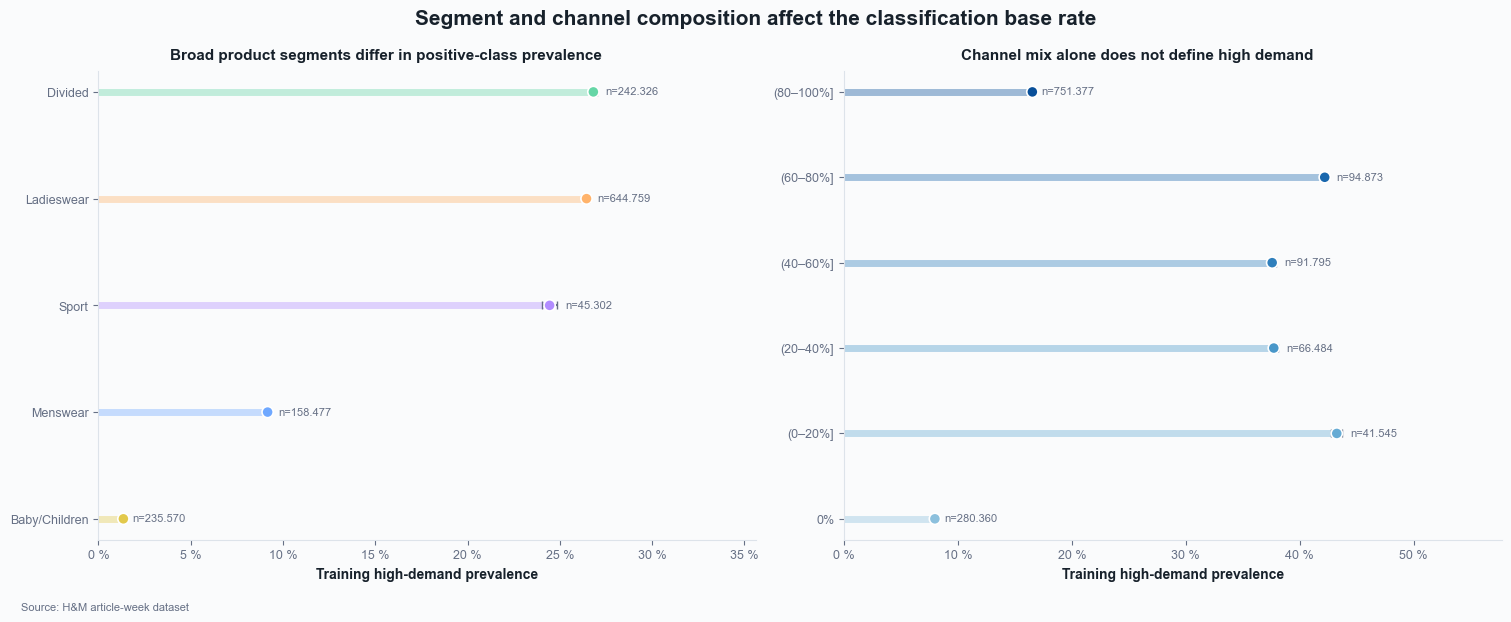

In [15]:
def prevalence_table(frame, group_column):
    result = frame.groupby(group_column, observed=True)[target].agg(
        article_weeks="size",
        high_demand_rows="sum",
        prevalence="mean",
    )
    lower, upper = wilson_interval(
        result["high_demand_rows"].to_numpy(),
        result["article_weeks"].to_numpy(),
    )
    result["lower_95"] = lower
    result["upper_95"] = upper
    return result

def draw_prevalence_intervals(ax, table, colors, xlabel):
    positions = np.arange(len(table))
    ax.hlines(
        positions, 0, table["prevalence"],
        color=colors, linewidth=5, alpha=.38, zorder=2,
    )
    ax.errorbar(
        table["prevalence"], positions,
        xerr=np.vstack([
            table["prevalence"] - table["lower_95"],
            table["upper_95"] - table["prevalence"],
        ]),
        fmt="none", ecolor=MUTED, elinewidth=1.5, capsize=3, zorder=3,
    )
    ax.scatter(
        table["prevalence"], positions,
        color=colors, edgecolor="white", linewidth=1.2, s=65, zorder=3,
    )
    for position, (_, row) in enumerate(table.iterrows()):
        ax.annotate(
            f"n={es(row['article_weeks']):,.0f}",
            (row["upper_95"], position),
            xytext=(6, 0), textcoords="offset points",
            va="center", color=MUTED, fontsize=8,
        )
    ax.set_yticks(positions, labels=table.index)
    ax.set_xlim(0, max(table["upper_95"].max() * 1.32, .05))
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    style_axis(ax, xlabel, "")
    ax.grid(axis="y", visible=False)

index_rates = prevalence_table(train, "index_group_name").sort_values("prevalence")
index_colors = PASTEL_RAINBOW[:len(index_rates)]

channel_labels = [
    "0%", "(0–20%]", "(20–40%]", "(40–60%]", "(60–80%]", "(80–100%]",
]
train["online_share_band"] = pd.cut(
    train["online_share"],
    bins=[-.001, 0, .2, .4, .6, .8, 1.000001],
    labels=channel_labels,
    include_lowest=True,
)
channel_rates = prevalence_table(train, "online_share_band").reindex(channel_labels)
channel_colors = plt.cm.Blues(np.linspace(.42, .88, len(channel_rates)))

display_es(index_rates.style.format({
    "article_weeks": "{:,.0f}",
    "high_demand_rows": "{:,.0f}",
    "prevalence": "{:.2%}",
    "lower_95": "{:.2%}",
    "upper_95": "{:.2%}",
}))
display_es(channel_rates.style.format({
    "article_weeks": "{:,.0f}",
    "high_demand_rows": "{:,.0f}",
    "prevalence": "{:.2%}",
    "lower_95": "{:.2%}",
    "upper_95": "{:.2%}",
}))

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), layout="constrained")
draw_prevalence_intervals(
    axes[0], index_rates, index_colors,
    "Training high-demand prevalence",
)
axes[0].set_title("Broad product segments differ in positive-class prevalence", fontweight="bold", color=INK)
draw_prevalence_intervals(
    axes[1], channel_rates, channel_colors,
    "Training high-demand prevalence",
)
axes[1].set_title("Channel mix alone does not define high demand", fontweight="bold", color=INK)
for ax in axes:
    center_axis_title(ax)
finish_figure(fig, "Segment and channel composition affect the classification base rate")
plt.show()


## 6. Segment-level stability across chronological splits

The following comparison keeps the mandatory train, validation, and test colours. Test rates are reported only as aggregate drift diagnostics; they must not be used to tune features, hyperparameters, class weights, or a probability threshold.


split,train,validation,test
index_group_name,,,
Baby/Children,"1,36%","0,39%","0,54%"
Menswear,"9,17%","11,24%","12,92%"
Sport,"24,44%","25,99%","27,87%"
Ladieswear,"26,44%","26,62%","25,39%"
Divided,"26,82%","24,67%","25,07%"


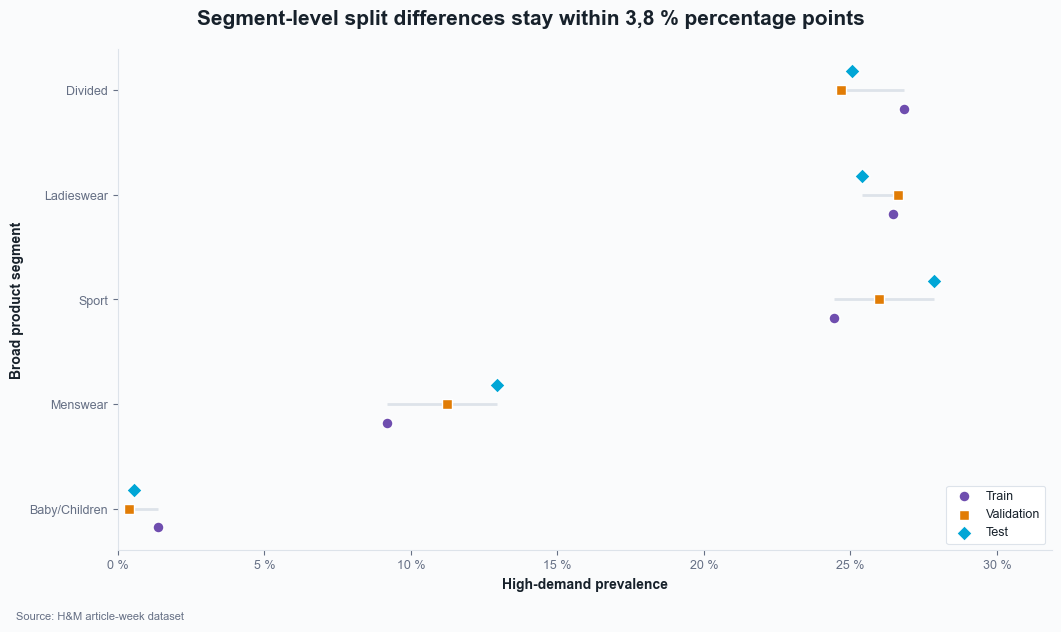

In [16]:
segment_split_rates = (
    data.groupby(["index_group_name", "split"], observed=True)[target]
    .mean()
    .unstack("split")
    .reindex(columns=split_order)
)
segment_order = (
    segment_split_rates["train"].sort_values().index.tolist()
)
segment_split_rates = segment_split_rates.loc[segment_order]
segment_gap = (
    segment_split_rates.max(axis=1) - segment_split_rates.min(axis=1)
)
display_es(segment_split_rates.style.format("{:.2%}"))

fig, ax = plt.subplots(figsize=(10.5, 6.3), layout="constrained")
positions = np.arange(len(segment_order))
offsets = {"train": -.18, "validation": 0, "test": .18}
markers = {"train": "o", "validation": "s", "test": "D"}
for position, group in enumerate(segment_order):
    values = segment_split_rates.loc[group, split_order]
    ax.hlines(
        position, values.min(), values.max(),
        color=GRID, linewidth=2, zorder=1,
    )
for split in split_order:
    ax.scatter(
        segment_split_rates[split],
        positions + offsets[split],
        color=SPLIT_COLORS[split],
        marker=markers[split], s=62,
        edgecolor="white", linewidth=1,
        label=split.title(), zorder=3,
    )
ax.set_yticks(positions, labels=segment_order)
ax.set_xlim(
    max(0, segment_split_rates.min().min() - .04),
    segment_split_rates.max().max() + .04,
)
ax.xaxis.set_major_formatter(PercentFormatter(1))
style_axis(ax, "High-demand prevalence", "Broad product segment")
ax.grid(axis="y", visible=False)
format_legend(ax, loc="lower right")
finish_figure(
    fig,
    f"Segment-level split differences stay within {es(segment_gap.max()):.1%} percentage points",
)
plt.show()


## 7. Baselines and metric implications

A majority classifier exposes why accuracy is insufficient. Three transparent history rules show how much signal exists before fitting a model. Validation results may guide model design; test results are deliberately excluded from this baseline comparison.


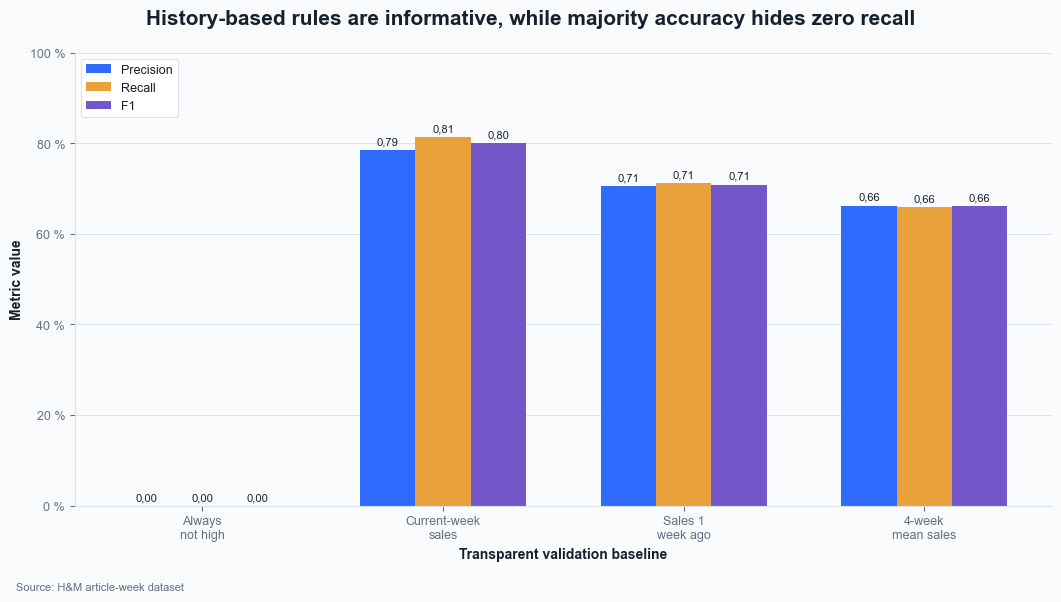

In [17]:
def metric_row(y_true, y_pred):
    return {
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
    }

baseline_rows = []
for split in ["train", "validation"]:
    frame = data.loc[data["split"].eq(split)]
    rules = {
        "Always not high": np.zeros(len(frame), dtype="int8"),
        "Current sales ≥ class threshold": frame["sales"].ge(threshold).astype("int8"),
        "Previous-week sales ≥ class threshold": frame["lag_1_sales"].ge(threshold).astype("int8"),
        "Four-week mean ≥ class threshold": frame["rolling_4w_sales_mean"].ge(threshold).astype("int8"),
    }
    for baseline, prediction in rules.items():
        baseline_rows.append({
            "split": split,
            "baseline": baseline,
            **metric_row(frame[target], prediction),
        })

baseline_metrics = (
    pd.DataFrame(baseline_rows)
    .set_index(["split", "baseline"])
)
display_es(baseline_metrics.style.format("{:.3f}"))

validation_metrics = baseline_metrics.loc["validation", ["precision", "recall", "f1"]]
fig, ax = plt.subplots(figsize=(10.5, 6), layout="constrained")
metric_colors = {"precision": BLUE, "recall": GOLD, "f1": VIOLET}
x = np.arange(len(validation_metrics))
width = .23
for index, metric in enumerate(validation_metrics.columns):
    values = validation_metrics[metric].to_numpy()
    bars = ax.bar(
        x + (index - 1) * width, values, width,
        color=metric_colors[metric], label=metric.title(), zorder=2,
    )
    for bar, value in zip(bars, values):
        ax.annotate(
            f"{es(value):.2f}",
            (bar.get_x() + bar.get_width() / 2, value),
            xytext=(0, 4), textcoords="offset points",
            ha="center", color=INK, fontsize=8,
        )
ax.set_xticks(x, labels=[
    "Always\nnot high",
    "Current-week\nsales",
    "Sales 1\nweek ago",
    "4-week\nmean sales",
])
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1))
style_axis(ax, "Transparent validation baseline", "Metric value")
format_legend(ax, loc="upper left")
finish_figure(fig, "History-based rules are informative, while majority accuracy hides zero recall")
plt.show()


## 8. Evidence-based conclusions for classification


In [18]:
prevalence_values = split_summary["prevalence"]
strongest_feature = feature_separation[
    "standardised_mean_difference"
].abs().idxmax()
strongest_label = feature_separation.loc[strongest_feature, "label"]
validation_majority_accuracy = 1 - prevalence_values.loc["validation"]
validation_pr_baseline = prevalence_values.loc["validation"]
best_validation_rule = (
    baseline_metrics.loc["validation", "f1"].drop("Always not high").idxmax()
)
best_validation_f1 = baseline_metrics.loc[
    ("validation", best_validation_rule), "f1"
]

display_es(Markdown(f"""
- **Class definition:** high demand means at least **{format_number(threshold)} recorded units in the next week**. The value is the higher-interpolated **{es(training_quantile):.0%} quantile of positive training demand** and is never recomputed on validation or test.
- **Imbalance:** prevalence is **{es(prevalence_values.loc['train']):.1%}** in training, **{es(prevalence_values.loc['validation']):.1%}** in validation, and **{es(prevalence_values.loc['test']):.1%}** in test. A validation majority classifier therefore reaches **{es(validation_majority_accuracy):.1%} accuracy with zero positive recall**.
- **Predictive structure:** the strongest univariate separation is **{strongest_label}**. Historical-demand signals dominate price and channel variables, but the analysis remains associational.
- **Segment stability:** the largest broad-segment prevalence spread across chronological splits is **{es(segment_gap.max()):.1%} percentage points**. Segment-level reporting remains necessary because aggregate metrics can conceal these differences.
- **Transparent baseline:** the best validation history rule by F1 is **{best_validation_rule}** with **F1 = {es(best_validation_f1):.3f}**. Learned models should improve on this rule as well as on the majority baseline.
- **Evaluation policy:** prioritise **Precision–Recall AUC** against its validation prevalence baseline of **{es(validation_pr_baseline):.1%}**, then report precision, recall, F1, balanced accuracy, confusion matrices, ROC-AUC, and calibration. Select the classifier probability threshold on validation data according to the relative cost of false positives and false negatives.
- **Guardrail:** keep the 16-unit class definition fixed while tuning the probability threshold. Do not use the final test period for feature selection, class weighting, hyperparameter tuning, or threshold selection.
- **Limitation:** recorded sales may be censored by stock availability and influenced by promotions or exposure that are absent from the data, so the class represents observed demand rather than unconstrained customer demand.
"""))



- **Class definition:** high demand means at least **16 recorded units in the next week**. The value is the higher-interpolated **75 % quantile of positive training demand** and is never recomputed on validation or test.
- **Imbalance:** prevalence is **19,9 %** in training, **21,3 %** in validation, and **21,1 %** in test. A validation majority classifier therefore reaches **78,7 % accuracy with zero positive recall**.
- **Predictive structure:** the strongest univariate separation is **Current-week sales**. Historical-demand signals dominate price and channel variables, but the analysis remains associational.
- **Segment stability:** the largest broad-segment prevalence spread across chronological splits is **3,8 % percentage points**. Segment-level reporting remains necessary because aggregate metrics can conceal these differences.
- **Transparent baseline:** the best validation history rule by F1 is **Current sales ≥ class threshold** with **F1 = 0,800**. Learned models should improve on this rule as well as on the majority baseline.
- **Evaluation policy:** prioritise **Precision–Recall AUC** against its validation prevalence baseline of **21,3 %**, then report precision, recall, F1, balanced accuracy, confusion matrices, ROC-AUC, and calibration. Select the classifier probability threshold on validation data according to the relative cost of false positives and false negatives.
- **Guardrail:** keep the 16-unit class definition fixed while tuning the probability threshold. Do not use the final test period for feature selection, class weighting, hyperparameter tuning, or threshold selection.
- **Limitation:** recorded sales may be censored by stock availability and influenced by promotions or exposure that are absent from the data, so the class represents observed demand rather than unconstrained customer demand.
